# Convolutional Neural Network — Stride Comparison

Source material: [`convolutions.ipynb`](https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition/blob/main/notebooks/02_deeplearning/02_cnn/convolutions.ipynb) and [`cnn.ipynb`](https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition/blob/main/notebooks/02_deeplearning/02_cnn/cnn.ipynb) from *Generative Deep Learning, 2nd Edition* (David Foster).

`convolutions.ipynb` demonstrates raw horizontal/vertical edge filters applied manually to a single image (no trainable model). The actual trainable CNN with `stride` as an architectural choice lives in the companion notebook `cnn.ipynb`, which trains a CIFAR-10 image classifier. Its `Conv2D` layers alternate `strides=1` (feature extraction) and `strides=2` (spatial downsampling).

This notebook builds **two versions** of that CNN:

1. **Original** — exactly as published in the book, downsampling `Conv2D` layers use `strides=2`.
2. **Custom stride** — identical architecture, but the downsampling `Conv2D` layers use `strides=3` instead of `2`.

Both are trained on CIFAR-10 for the same number of epochs, then evaluated and compared.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, optimizers, utils, datasets

NUM_CLASSES = 10
EPOCHS = 10
BATCH_SIZE = 32

## 1. Prepare the Data

In [2]:
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train_cat = utils.to_categorical(y_train, NUM_CLASSES)
y_test_cat = utils.to_categorical(y_test, NUM_CLASSES)

CLASSES = np.array([
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
])

print("x_train:", x_train.shape, "x_test:", x_test.shape)

A local file was found, but it seems to be incomplete or outdated because the auto file hash does not match the original value of 6d958be074577803d12ecdefd02955f39262c83c16fe9348329d7fe0b5c001ce so we will re-download the data.


x_train: (50000, 32, 32, 3) x_test: (10000, 32, 32, 3)


## 2. Model Builder

Same architecture as the book's `cnn.ipynb`, parameterised by `stride` so we can build both versions from one function.

In [3]:
def build_model(stride, name):
    input_layer = layers.Input((32, 32, 3))

    x = layers.Conv2D(filters=32, kernel_size=3, strides=1, padding="same")(input_layer)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2D(filters=32, kernel_size=3, strides=stride, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2D(filters=64, kernel_size=3, strides=1, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2D(filters=64, kernel_size=3, strides=stride, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Flatten()(x)

    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Dropout(rate=0.5)(x)

    x = layers.Dense(NUM_CLASSES)(x)
    output_layer = layers.Activation("softmax")(x)

    model = models.Model(input_layer, output_layer, name=name)
    opt = optimizers.Adam(learning_rate=0.0005)
    model.compile(loss="categorical_crossentropy", optimizer=opt, metrics=["accuracy"])
    return model

## 3. Version A — Original (stride = 2)

In [4]:
model_original = build_model(stride=2, name="cnn_stride2_original")
model_original.summary()

Model: "cnn_stride2_original"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 592,554 (2.26 MB)

 Trainable params: 591,914 (2.26 MB)

 Non-trainable params: 640 (2.50 KB)

In [5]:
history_original = model_original.fit(
    x_train,
    y_train_cat,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    validation_data=(x_test, y_test_cat),
)

Epoch 1/10


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.3859 - loss: 1.7939 - val_accuracy: 0.5672 - val_loss: 1.2203


Epoch 2/10


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.5878 - loss: 1.1662 - val_accuracy: 0.5986 - val_loss: 1.2206


Epoch 3/10


...

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.7561 - loss: 0.6931 - val_accuracy: 0.6962 - val_loss: 0.8948


Epoch 9/10


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.7678 - loss: 0.6663 - val_accuracy: 0.7224 - val_loss: 0.8107


Epoch 10/10


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.7792 - loss: 0.6275 - val_accuracy: 0.7278 - val_loss: 0.7981


In [6]:
eval_original = model_original.evaluate(x_test, y_test_cat, batch_size=1000)
print("Original (stride=2) -> loss: %.4f, accuracy: %.4f" % tuple(eval_original))

 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7400 - loss: 0.7297

 3/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7356 - loss: 0.7575

 5/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7319 - loss: 0.7737

 7/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7298 - loss: 0.7808

 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7289 - loss: 0.7853

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7287 - loss: 0.7876


Original (stride=2) -> loss: 0.7981, accuracy: 0.7278


## 4. Version B — Custom Stride (stride = 3)

In [7]:
model_custom = build_model(stride=3, name="cnn_stride3_custom")
model_custom.summary()

Model: "cnn_stride3_custom"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 11, 11, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 199,338 (778.66 KB)

 Trainable params: 198,698 (776.16 KB)

 Non-trainable params: 640 (2.50 KB)

In [8]:
history_custom = model_custom.fit(
    x_train,
    y_train_cat,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    validation_data=(x_test, y_test_cat),
)

Epoch 1/10


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.3497 - loss: 1.9201 - val_accuracy: 0.5124 - val_loss: 1.3349


Epoch 2/10


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 232s 148ms/step - accuracy: 0.5263 - loss: 1.3256 - val_accuracy: 0.5918 - val_loss: 1.1479


Epoch 3/10


...

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.7110 - loss: 0.8299 - val_accuracy: 0.6606 - val_loss: 0.9668


Epoch 9/10


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.7244 - loss: 0.7866 - val_accuracy: 0.6243 - val_loss: 1.1198


Epoch 10/10


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.7306 - loss: 0.7662 - val_accuracy: 0.6552 - val_loss: 1.0088


In [9]:
eval_custom = model_custom.evaluate(x_test, y_test_cat, batch_size=1000)
print("Custom (stride=3) -> loss: %.4f, accuracy: %.4f" % tuple(eval_custom))

 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6450 - loss: 0.9807

 4/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6501 - loss: 0.9953

 7/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6543 - loss: 0.9965

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6551 - loss: 0.9984

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6551 - loss: 0.9994


Custom (stride=3) -> loss: 1.0088, accuracy: 0.6552


## 5. Compare Output Shapes and Parameter Counts

In [10]:
def flatten_shape(model):
    for layer in model.layers:
        if isinstance(layer, layers.Flatten):
            return layer.output.shape

print("Original (stride=2) flattened feature shape:", flatten_shape(model_original))
print("Custom   (stride=3) flattened feature shape:", flatten_shape(model_custom))
print()
print("Original (stride=2) total params:", model_original.count_params())
print("Custom   (stride=3) total params:", model_custom.count_params())

Original (stride=2) flattened feature shape: (None, 4096)
Custom   (stride=3) flattened feature shape: (None, 1024)

Original (stride=2) total params: 592554
Custom   (stride=3) total params: 199338


## 6. Compare Training Curves

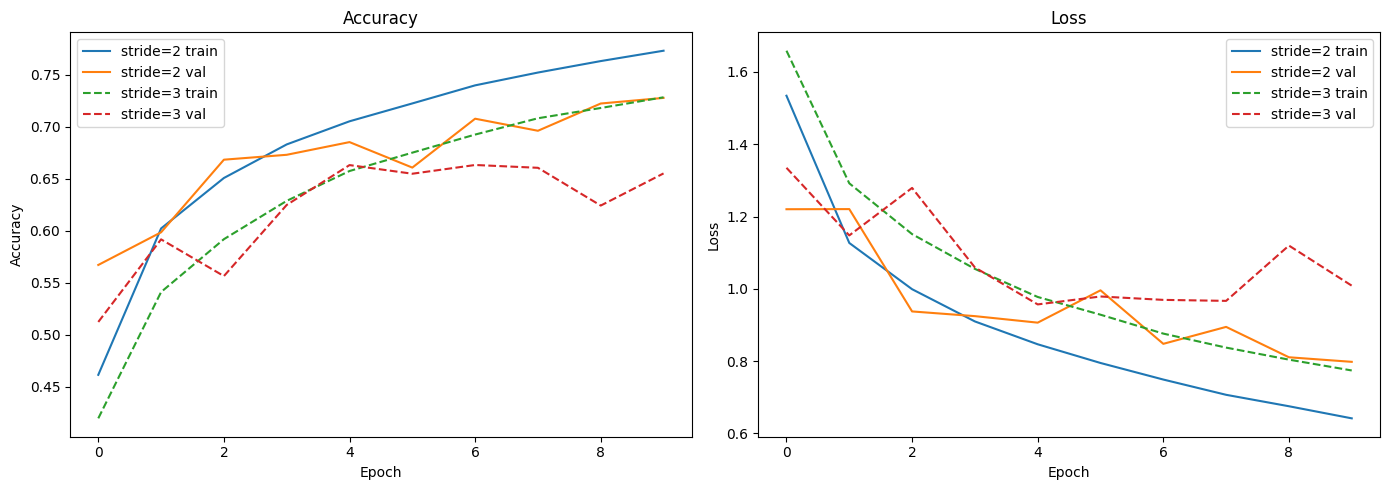

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_original.history["accuracy"], label="stride=2 train")
axes[0].plot(history_original.history["val_accuracy"], label="stride=2 val")
axes[0].plot(history_custom.history["accuracy"], label="stride=3 train", linestyle="--")
axes[0].plot(history_custom.history["val_accuracy"], label="stride=3 val", linestyle="--")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history_original.history["loss"], label="stride=2 train")
axes[1].plot(history_original.history["val_loss"], label="stride=2 val")
axes[1].plot(history_custom.history["loss"], label="stride=3 train", linestyle="--")
axes[1].plot(history_custom.history["val_loss"], label="stride=3 val", linestyle="--")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("stride_comparison.png", dpi=120)
plt.show()

## 7. Sample Predictions Side by Side

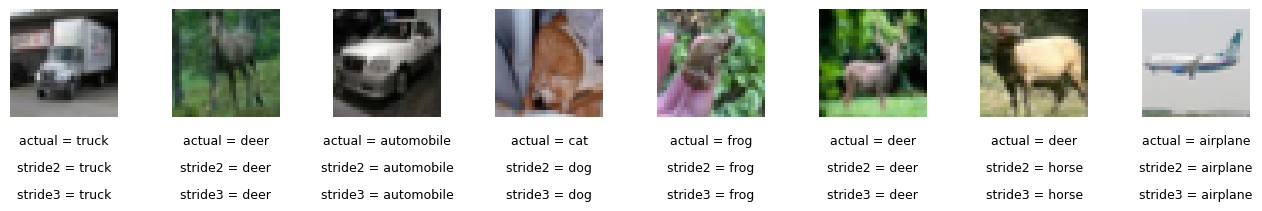

In [12]:
preds_original = model_original.predict(x_test)
preds_custom = model_custom.predict(x_test)

preds_original_single = CLASSES[np.argmax(preds_original, axis=-1)]
preds_custom_single = CLASSES[np.argmax(preds_custom, axis=-1)]
actual_single = CLASSES[np.argmax(y_test_cat, axis=-1)]

n_to_show = 8
np.random.seed(42)
indices = np.random.choice(range(len(x_test)), n_to_show)

fig = plt.figure(figsize=(16, 4))
fig.subplots_adjust(hspace=0.6, wspace=0.5)
for i, idx in enumerate(indices):
    img = x_test[idx]
    ax = fig.add_subplot(1, n_to_show, i + 1)
    ax.axis("off")
    ax.text(0.5, -0.25, "actual = " + str(actual_single[idx]), fontsize=9, ha="center", transform=ax.transAxes)
    ax.text(0.5, -0.5, "stride2 = " + str(preds_original_single[idx]), fontsize=9, ha="center", transform=ax.transAxes)
    ax.text(0.5, -0.75, "stride3 = " + str(preds_custom_single[idx]), fontsize=9, ha="center", transform=ax.transAxes)
    ax.imshow(img)
plt.savefig("sample_predictions.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Interpretation of Observations

**Measured results (10 epochs, CIFAR-10 test set):**

| | Original (stride=2) | Custom (stride=3) |
|---|---|---|
| Flattened feature shape | (None, 4096) | (None, 1024) |
| Total parameters | 592,554 | 199,338 |
| Final train accuracy | 0.7792 | 0.7306 |
| Final val/test accuracy | **0.7278** | **0.6552** |
| Final val/test loss | 0.7981 | 1.0088 |
| Time per epoch (this machine) | ~13s | ~10s |

**Output shapes and parameter count.** The `stride` argument in `Conv2D` controls how far the filter window moves at each step. With `strides=2`, the two downsampling layers shrink the 32×32 input to 16×16 then 8×8, giving a flattened feature vector of 8·8·64 = 4096 values feeding the dense head (592k parameters total). Pushing `strides=3` downsamples more aggressively — 32 → 11 → 4 (using `ceil(in/stride)` under `"same"` padding) — giving a flattened vector of only 4·4·64 = 1024 values and roughly a third of the parameters (199k). This is a purely mechanical/architectural effect of the stride formula, independent of training.

**Accuracy.** The stride-2 original reached **72.8% test accuracy** vs. **65.5%** for the stride-3 version — a ~7.3 point gap after the same 10 epochs. Each strided convolution in the stride-3 model discards more spatial detail per step than stride-2 does, so by the time features reach the dense layers, fine edges and textures needed to separate visually similar classes (cat vs. dog, automobile vs. truck) have been compressed away more aggressively. The stride-3 model's validation curve was also visibly noisier — e.g. it dipped to 62.4% at epoch 9 (val loss spiking to 1.12) before partially recovering at epoch 10 — consistent with a model that has less redundant spatial information to fall back on, making its validation performance more sensitive to which examples land in each batch.

**Train/val gap.** The original model's train-val accuracy gap was ~5.1 points (77.9% → 72.8%); the stride-3 model's gap was larger at ~7.5 points (73.1% → 65.5%), even though it has fewer parameters. This shows that "fewer parameters" does not automatically mean "less overfitting" — what matters more here is that the aggressively downsampled feature maps are a worse representation of the input overall, so both training and validation accuracy suffer, and the relationship between them is noisier.

**Speed/size trade-off.** The stride-3 model trained faster per epoch (~10s vs. ~13s) and is ~3x smaller, because its feature maps and dense layer are smaller. This is the classic strided-convolution trade-off: a larger stride buys you a smaller, cheaper model at the cost of spatial resolution and, in this case, a meaningful chunk of accuracy. Stride 2 is the default in the book's architecture precisely because it halves resolution in a controlled, evenly-divisible way (32→16→8) without discarding as much information as a larger stride; stride 3 does not evenly divide 32, compounding the information loss with imprecise binning at each step.